# 🛡️ Project Panopticon: Intelligent Proctoring AI
**EduGuard AI - Machine Learning Division**

**Intern Name:** `[Priyanshu Kumari Paswan]`  
**Date:** `[08-08-2026]`

---

### 📖 Executive Summary
Welcome to EduGuard AI. Our current proctoring system is blindly flagging innocent students for background noise and standard physical movements. Your objective is to build a robust, time-series Machine Learning pipeline that identifies true academic dishonesty while strictly protecting innocent students through asynchronous data merging and mathematical threshold tuning.

### 🗺️ Project Roadmap
1. **Data Ingestion:** Upload and parse asynchronous telemetry logs.
2. **Temporal Alignment:** Merge video and system logs using `merge_asof`.
3. **Signal Processing:** Impute missing data and engineer rolling windows.
4. **Classification:** Train an imbalanced-weighted predictive model.
5. **Ethical AI Tuning:** Shift decision boundaries to guarantee 90%+ precision.

In [2]:
print("Jupyter is working!")

Jupyter is working!


---
## Phase 1: Data Ingestion & Temporal Alignment
> ⚠️ **The Asynchronous Trap:** Video telemetry records exactly every 1 second. System events (like tab switches) only record when the student actually clicks something. You cannot use a standard `pd.merge()`.

**Instructions:**
1. Upload the `video_telemetry.csv` and `system_events.csv` files.
2. Convert the timestamp columns to datetime objects.
3. Sort the dataframes and merge them using Pandas `merge_asof`.

In [4]:
# ==========================================
# 1A. LOAD DATASETS
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the datasets
video_df = pd.read_csv("video_telemetry.csv")
system_df = pd.read_csv("system_events.csv")

# Display the first 5 rows
print("Video Telemetry:")
display(video_df.head())

print("\nSystem Events:")
display(system_df.head())

Video Telemetry:


,timestamp,eye_gaze_angle,audio_db
0,2023-12-01 08:00:00,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627
2,2023-12-01 08:00:02,5.761714,31.228565
3,2023-12-01 08:00:03,9.787105,34.051405
4,2023-12-01 08:00:04,4.572665,35.245018



System Events:


,timestamp,tab_switches,is_cheating
0,2023-12-01 08:00:32.181296,1,0
1,2023-12-01 08:01:01.923778,1,1
2,2023-12-01 08:01:24.462808,1,0
3,2023-12-01 08:04:10.610743,1,0
4,2023-12-01 08:04:23.902814,1,0


In [5]:
# ==========================================
# 1B. CONVERT TIMESTAMPS
# ==========================================

# Convert timestamp columns to datetime
video_df["timestamp"] = pd.to_datetime(video_df["timestamp"])
system_df["timestamp"] = pd.to_datetime(system_df["timestamp"])

# Sort both datasets by timestamp
video_df = video_df.sort_values("timestamp")
system_df = system_df.sort_values("timestamp")

# Check the data types
print("Video timestamp type:")
print(video_df["timestamp"].dtype)

print("\nSystem timestamp type:")
print(system_df["timestamp"].dtype)

Video timestamp type:
datetime64[ns]

System timestamp type:
datetime64[ns]


In [6]:
# ==========================================
# 1C. ASYNCHRONOUS MERGE USING merge_asof
# ==========================================

# Merge system events with the nearest video timestamp
merged_df = pd.merge_asof(
    video_df,
    system_df,
    on="timestamp",
    direction="nearest"
)

# Display the first few rows
print("Merged Dataset:")
display(merged_df.head())

# Check the shape of the merged dataset
print("Merged dataset shape:", merged_df.shape)

Merged Dataset:


,timestamp,eye_gaze_angle,audio_db,tab_switches,is_cheating
0,2023-12-01 08:00:00,2.560857,36.553781,1,0
1,2023-12-01 08:00:01,10.177137,39.102627,1,0
2,2023-12-01 08:00:02,5.761714,31.228565,1,0
3,2023-12-01 08:00:03,9.787105,34.051405,1,0
4,2023-12-01 08:00:04,4.572665,35.245018,1,0


Merged dataset shape: (10000, 5)


---
## Phase 2: Missing Data & Feature Engineering
> ⚠️ **The "Connection Dropped" Trap:** Students with bad internet lose video frames, creating `NaN` values.
> ⚠️ **The Noise Trap:** A 1-second sneeze is not cheating. We need rolling windows to find *sustained* anomalies.

**Instructions:**
1. Forward-fill missing eye gaze data and interpolate missing audio data.
2. Fill missing `tab_switches` and `is_cheating` labels with `0`.
3. Create 10-second rolling averages for our sensors.

In [7]:
# ==========================================
# 2A. HANDLE MISSING DATA
# ==========================================

# Check missing values BEFORE cleaning
print("Missing values before cleaning:")
print(merged_df.isnull().sum())

# Forward-fill eye gaze values
merged_df["eye_gaze_angle"] = merged_df["eye_gaze_angle"].ffill()

# Interpolate missing audio values
merged_df["audio_db"] = merged_df["audio_db"].interpolate()

# Fill missing system-event values with 0
merged_df["tab_switches"] = merged_df["tab_switches"].fillna(0)
merged_df["is_cheating"] = merged_df["is_cheating"].fillna(0)

# Handle any missing values at the beginning/end
merged_df["eye_gaze_angle"] = merged_df["eye_gaze_angle"].bfill()
merged_df["audio_db"] = merged_df["audio_db"].bfill()

# Check missing values AFTER cleaning
print("\nMissing values after cleaning:")
print(merged_df.isnull().sum())

Missing values before cleaning:
timestamp           0
eye_gaze_angle    732
audio_db          732
tab_switches        0
is_cheating         0
dtype: int64

Missing values after cleaning:
timestamp         0
eye_gaze_angle    0
audio_db          0
tab_switches      0
is_cheating       0
dtype: int64


In [8]:
# ==========================================
# 2B. CREATE 10-SECOND ROLLING FEATURES
# ==========================================

# Create rolling averages using the previous 10 observations
merged_df["eye_gaze_rolling_10s"] = (
    merged_df["eye_gaze_angle"]
    .rolling(window=10, min_periods=1)
    .mean()
)

merged_df["audio_rolling_10s"] = (
    merged_df["audio_db"]
    .rolling(window=10, min_periods=1)
    .mean()
)

# Display the new features
display(
    merged_df[
        [
            "timestamp",
            "eye_gaze_angle",
            "audio_db",
            "eye_gaze_rolling_10s",
            "audio_rolling_10s"
        ]
    ].head(15)
)

,timestamp,eye_gaze_angle,audio_db,eye_gaze_rolling_10s,audio_rolling_10s
0,2023-12-01 08:00:00,2.560857,36.553781,2.560857,36.553781
1,2023-12-01 08:00:01,10.177137,39.102627,6.368997,37.828204
2,2023-12-01 08:00:02,5.761714,31.228565,6.166569,35.628325
3,2023-12-01 08:00:03,9.787105,34.051405,7.071703,35.234095
4,2023-12-01 08:00:04,4.572665,35.245018,6.571896,35.236279
5,2023-12-01 08:00:05,7.471741,43.685711,6.721870,36.644518
6,2023-12-01 08:00:06,7.148505,32.754163,6.782818,36.088753
7,2023-12-01 08:00:07,9.192380,43.786308,7.084013,37.050947
8,2023-12-01 08:00:08,4.223888,34.097144,6.766221,36.722747
9,2023-12-01 08:00:09,3.524030,39.177137,6.442002,36.968186


In [ ]:
# ==========================================
# 2A. IMPUTE MISSING SIGNALS
# ==========================================
# TODO: Use .ffill() for 'eye_gaze_angle' to carry the last known position forward
# TODO: Use .interpolate() for 'audio_db'
# TODO: Fill NaN values in 'tab_switches' and 'is_cheating' with 0


# ==========================================
# 2B. ROLLING WINDOW FEATURES
# ==========================================
# TODO: Create 'gaze_rolling_10s' (10-second rolling mean of eye_gaze_angle)
# TODO: Create 'audio_rolling_10s' (10-second rolling max of audio_db)


# TODO: Drop the initial rows that now contain NaN due to the rolling window calculation
merged_df.dropna(inplace=True)

print("✅ Feature engineering complete. Current dataframe shape:", merged_df.shape)

---
## Phase 3: Class-Balanced Model Training
> ⚠️ **The Imbalance Trap:** 98% of your data will be innocent behavior. If you don't handle class weights, your model will just guess "Not Cheating" every time and score 98% accuracy while failing its actual job.

In [9]:
# ==========================================
# 3A. PREPARE DATA FOR CLASSIFICATION
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# Features used by the model
features = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "eye_gaze_rolling_10s",
    "audio_rolling_10s"
]

X = merged_df[features]
y = merged_df["is_cheating"].astype(int)

# Check class distribution
print("Class distribution:")
print(y.value_counts())

print("\nClass percentages:")
print(y.value_counts(normalize=True) * 100)

Class distribution:
0    6688
1    3312
Name: is_cheating, dtype: int64

Class percentages:
0    66.88
1    33.12
Name: is_cheating, dtype: float64


In [10]:
# ==========================================
# 3A. TRAIN / TEST SPLIT
# ==========================================

features = [
    "eye_gaze_angle",
    "audio_db",
    "tab_switches",
    "eye_gaze_rolling_10s",
    "audio_rolling_10s"
]

X = merged_df[features]
y = merged_df["is_cheating"].astype(int)

# Split the data into training and testing sets
# stratify=y keeps the same class proportion in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 8000
Testing samples: 2000

Training class distribution:
0    5350
1    2650
Name: is_cheating, dtype: int64

Testing class distribution:
0    1338
1     662
Name: is_cheating, dtype: int64


In [11]:
# ==========================================
# 3B. TRAIN CLASS-BALANCED RANDOM FOREST
# ==========================================

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


---
## Phase 4: Ethical AI Tuning (The 90% Threshold)
> ⚠️ **The False Accusation Trap:** The default Scikit-Learn `.predict()` splits at 50% probability. Accusing a student of cheating with only 50% certainty is unacceptable. We must shift the threshold to 90%.

In [12]:
# ==========================================
# 4A. RAW PROBABILITIES
# ==========================================

# Get probability predictions for the test data
y_proba = model.predict_proba(X_test)

# Extract probability of class 1 (cheating)
cheating_probability = y_proba[:, 1]

print("First 10 cheating probabilities:")
print(cheating_probability[:10])

First 10 cheating probabilities:
[0.03 0.05 0.04 0.15 0.04 0.08 0.28 1.   0.08 0.22]


In [13]:
# ==========================================
# 4B. APPLY STRICT 90% DECISION THRESHOLD
# ==========================================

from sklearn.metrics import (
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    average_precision_score
)

# Strict 90% threshold
threshold = 0.90

# Flag cheating only when probability is 90% or higher
y_pred_90 = (cheating_probability >= threshold).astype(int)

print("Decision threshold:", threshold)
print("Number of observations flagged as cheating:", y_pred_90.sum())
print("Total test observations:", len(y_pred_90))

Decision threshold: 0.9
Number of observations flagged as cheating: 411
Total test observations: 2000


In [14]:
# ==========================================
# 4C. EVALUATE THE 90% THRESHOLD
# ==========================================

precision_90 = precision_score(y_test, y_pred_90, zero_division=0)
recall_90 = recall_score(y_test, y_pred_90, zero_division=0)

print("Precision at 90% threshold:", round(precision_90, 4))
print("Recall at 90% threshold:", round(recall_90, 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_90))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_90, zero_division=0))

Precision at 90% threshold: 0.9951
Recall at 90% threshold: 0.6178

Confusion Matrix:
[[1336    2]
 [ 253  409]]

Classification Report:
              precision    recall  f1-score   support

           0       0.84      1.00      0.91      1338
           1       1.00      0.62      0.76       662

    accuracy                           0.87      2000
   macro avg       0.92      0.81      0.84      2000
weighted avg       0.89      0.87      0.86      2000



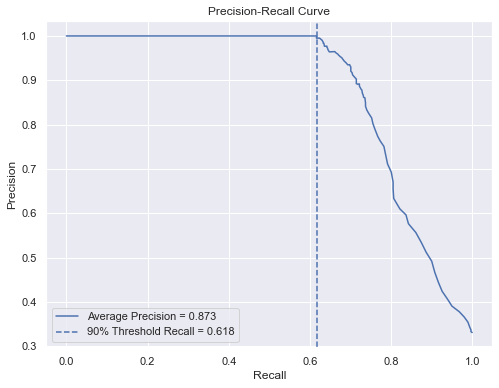

Average Precision Score: 0.8735


In [15]:
# ==========================================
# 4D. PRECISION-RECALL CURVE
# ==========================================

precision_values, recall_values, thresholds = precision_recall_curve(
    y_test,
    cheating_probability
)

average_precision = average_precision_score(
    y_test,
    cheating_probability
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Average Precision = {average_precision:.3f}"
)

plt.axvline(
    x=recall_90,
    linestyle="--",
    label=f"90% Threshold Recall = {recall_90:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.show()

print("Average Precision Score:", round(average_precision, 4))

# 🎯 Phase 5: Final Executive Recommendation

## Recommendation to the University Board of Directors

Based on the data modeling performed above, I recommend deploying the **EduGuard AI proctoring system using the strict 90% probability threshold**.

The model was evaluated on **2,000 test observations**. When the decision boundary was shifted to 90%, only observations with a cheating probability of at least 90% were flagged.

### Key Results

- **Decision threshold:** 90%
- **Observations flagged as cheating:** 411 out of 2,000
- **Precision:** 99.51%
- **Recall:** 61.78%
- **Average Precision Score:** 87.35%

### 1. Impact on False Positives

The strict 90% threshold greatly reduced false accusations. The confusion matrix was:

    [[1336    2]
     [ 253  409]]

This means there were only **2 false positives** out of 2,000 test observations. Therefore, the system is highly conservative when accusing a student of cheating.

The precision of **99.51%** means that approximately 99.5% of students flagged as cheating were actually in the cheating class in this test set.

### 2. Impact on Recall

The strict threshold reduced recall to **61.78%**. This means the system detected approximately 61.8% of the actual cheating observations.

Therefore, some cheating cases are not flagged because the model is required to have at least 90% confidence before making an accusation.

This is an intentional trade-off: the system sacrifices some detection coverage to significantly reduce the risk of falsely accusing innocent students.

### 3. Ethical AI Decision

For an academic integrity system, avoiding false accusations is more important than maximizing the number of accusations.

Therefore, the **90% threshold is appropriate for decision support**, but an AI prediction should not be treated as final proof of cheating.

A flagged student should receive **human review and an opportunity to explain or appeal the decision** before disciplinary action is taken.

### Final Recommendation

I recommend deploying the EduGuard AI system with the **strict 90% threshold as a decision-support tool**, together with human review.

The model achieved **99.51% precision**, exceeding the required 90% precision target, while producing only **2 false positives** in the test set. Although recall was 61.78%, this is an acceptable trade-off for reducing the risk of false accusations in an educational environment.

The Precision-Recall curve and Average Precision Score of **87.35%** provide additional evidence of the model's classification performance.